In [85]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    PolynomialFeatures
)

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 100)

%matplotlib inline

print(pd.__version__)

3.0.5


In [86]:
df = pd.read_csv('CreditScore.csv')

C:\Users\mubee\AppData\Local\Temp\ipykernel_2560\854442854.py:1: DtypeWarning: Columns (0: Gender) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('CreditScore.csv')


In [87]:
print("head:")
display(df.head())

print("Table Size:",df.shape)
print("Columns: ",df.columns.to_list())
print("...................Data types................\n",df.dtypes)
print("...................Table info:...............\n",df.info)
display(df.describe(include='all'))


head:


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Gender,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,f,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,m,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,f,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,m,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,f,49,1,0.024926,63588.0,7,0,1,0,0.0


Table Size: (150000, 13)
Columns:  ['Id', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'Gender', 'Age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
...................Data types................
 Id                                        int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
Gender                                      str
Age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents              

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Gender,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,307,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
unique,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,223,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,75000.500000,0.066840,6.048438,NaN,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,NaN,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,NaN,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,NaN,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,NaN,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000


In [88]:
# df.isnull().sum()
missing_count = df.isnull().sum()

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percent
})

display(missing_report)

,Missing_Count,Missing_Percentage
Id,0,0.000000
SeriousDlqin2yrs,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
Gender,149693,99.795333
Age,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
DebtRatio,0,0.000000
MonthlyIncome,29731,19.820667
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000


In [89]:
print("Duplicate Rows:",df.duplicated().sum())
print("Unique Rows:",df.nunique().sum())
df.nunique()

Duplicate Rows: 0
Unique Rows: 403753


Id                                      150000
SeriousDlqin2yrs                             2
RevolvingUtilizationOfUnsecuredLines    125728
Gender                                       2
Age                                         86
NumberOfTime30-59DaysPastDueNotWorse        16
DebtRatio                               114194
MonthlyIncome                            13594
NumberOfOpenCreditLinesAndLoans             58
NumberOfTimes90DaysLate                     19
NumberRealEstateLoansOrLines                28
NumberOfTime60-89DaysPastDueNotWorse        13
NumberOfDependents                          13
dtype: int64

In [90]:
#df["SeriousDlqin2yrs"].value_counts()
df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

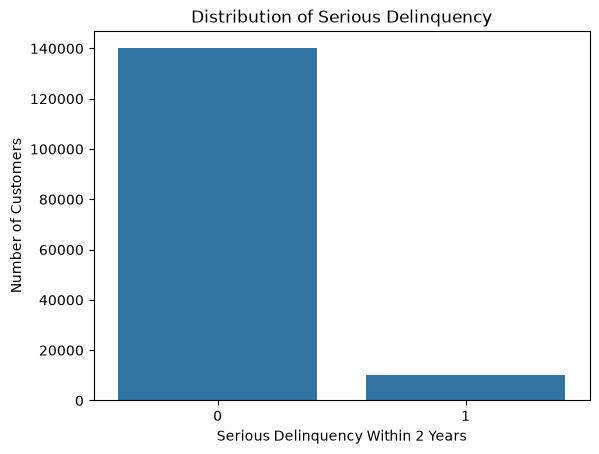

In [91]:
sns.countplot(data=df, x="SeriousDlqin2yrs")

plt.title("Distribution of Serious Delinquency")
plt.xlabel("Serious Delinquency Within 2 Years")
plt.ylabel("Number of Customers")

plt.show()

Key Insight: The target variable is imbalanced, with substantially more customers having no serious delinquency than customers experiencing serious delinquency. This imbalance should be considered during future machine-learning modeling.

In [92]:
df["Age"].describe()

count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: Age, dtype: float64

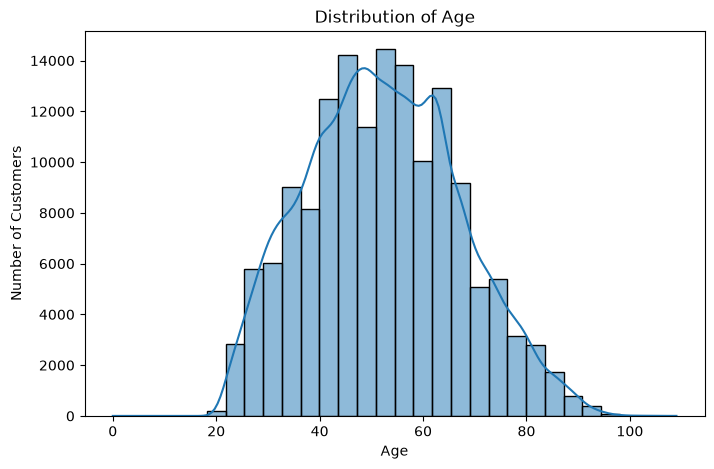

In [93]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

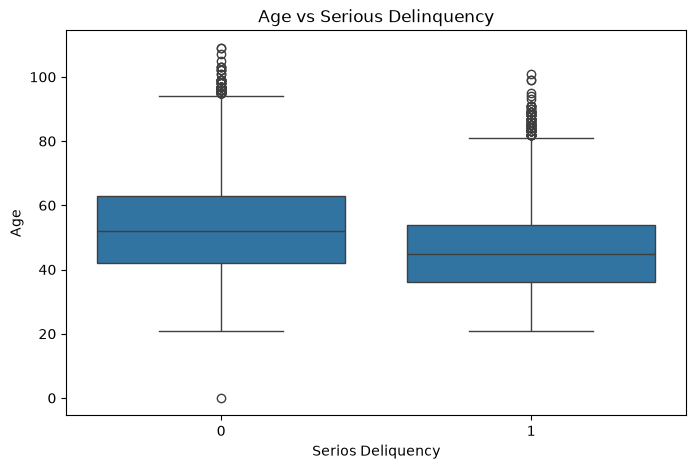

In [94]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="SeriousDlqin2yrs", y="Age")

plt.title("Age vs Serious Delinquency")
plt.xlabel("Serios Deliquency")
plt.ylabel("Age")

plt.show()

In [95]:
df["MonthlyIncome"].describe()

count    1.202690e+05
mean     6.670221e+03
std      1.438467e+04
min      0.000000e+00
25%      3.400000e+03
50%      5.400000e+03
75%      8.249000e+03
max      3.008750e+06
Name: MonthlyIncome, dtype: float64

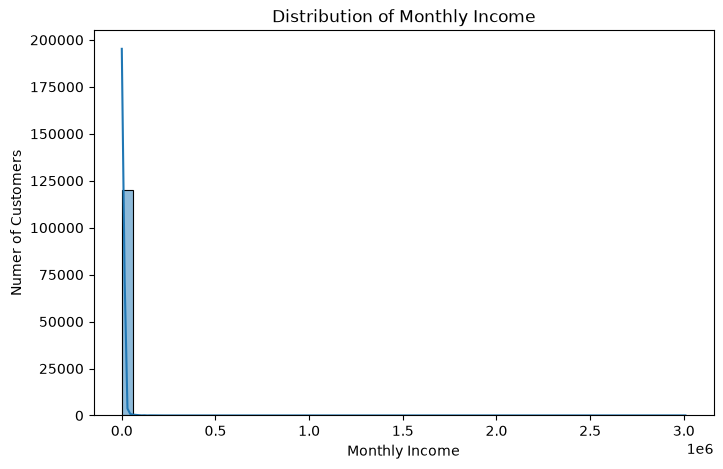

In [96]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x= "MonthlyIncome", bins=50, kde=True)

plt.title("Distribution of Monthly Income")
plt.xlabel("Monthly Income")
plt.ylabel("Numer of Customers")
plt.show()

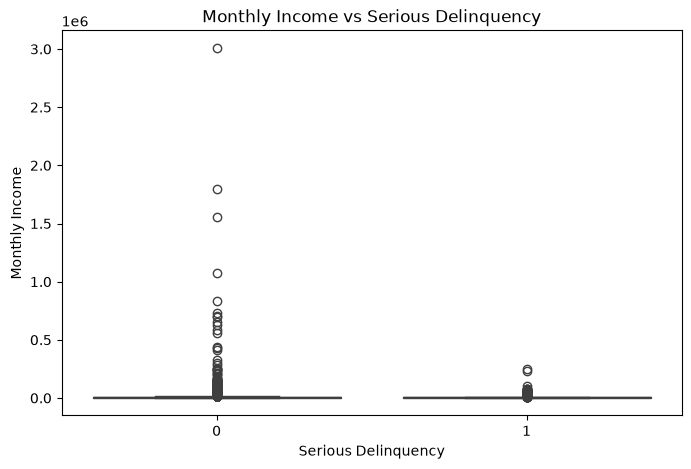

In [97]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="SeriousDlqin2yrs", y="MonthlyIncome")

plt.title("Monthly Income vs Serious Delinquency")
plt.xlabel("Serious Delinquency")
plt.ylabel("Monthly Income")

plt.show()

In [98]:
df["DebtRatio"].describe()

count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max      329664.000000
Name: DebtRatio, dtype: float64

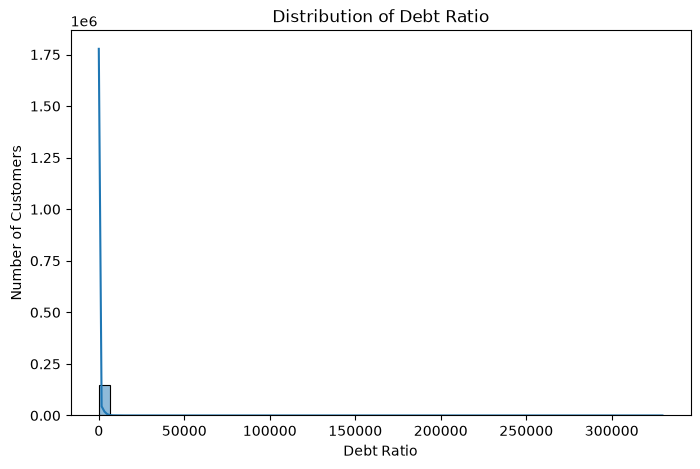

In [99]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="DebtRatio", bins=50, kde=True)

plt.title("Distribution of Debt Ratio")
plt.xlabel("Debt Ratio")
plt.ylabel("Number of Customers")

plt.show()

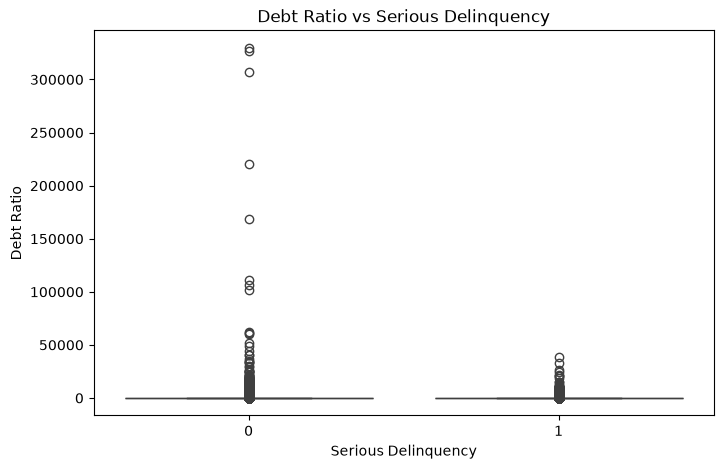

In [100]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="SeriousDlqin2yrs",
    y="DebtRatio"
)

plt.title("Debt Ratio vs Serious Delinquency")
plt.xlabel("Serious Delinquency")
plt.ylabel("Debt Ratio")

plt.show()

In [101]:
important_vars = [
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents"
]

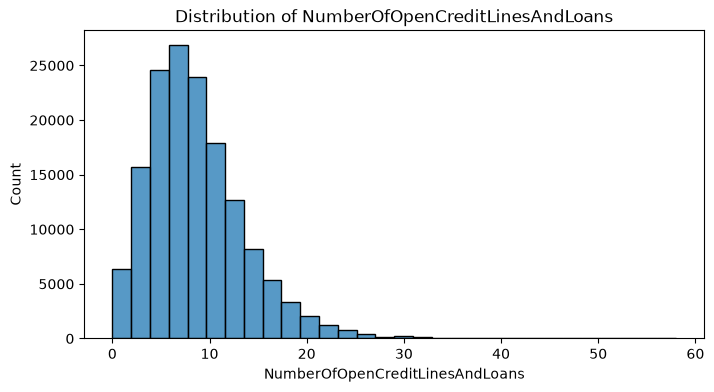

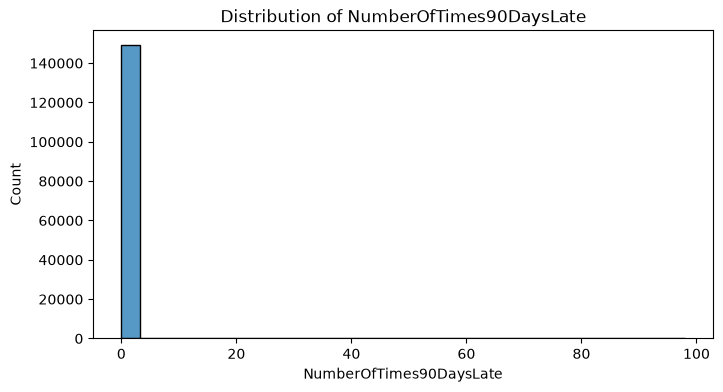

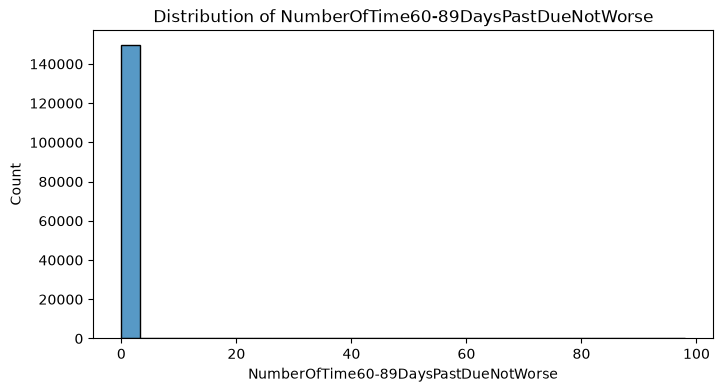

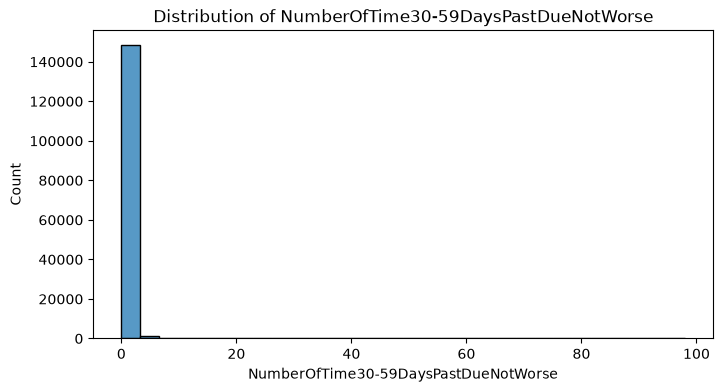

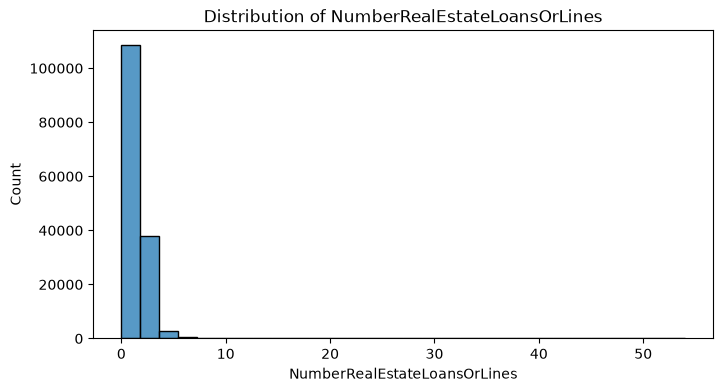

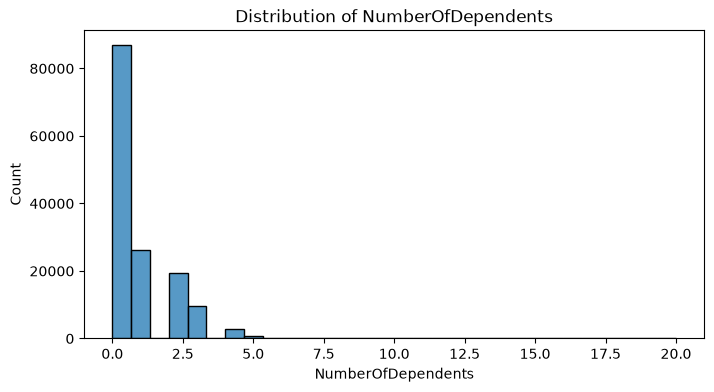

In [102]:
for col in important_vars:
    plt.figure(figsize=(8,4))
    sns.histplot(data=df, x=col, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

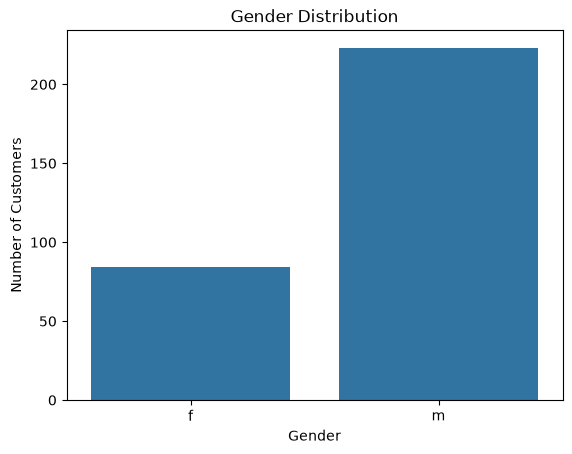

In [103]:
df["Gender"].value_counts()
sns.countplot(data=df, x="Gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

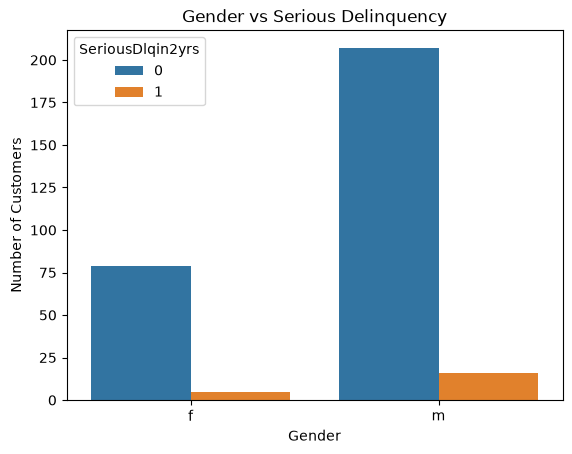

In [104]:
sns.countplot(
    data=df,
    x="Gender",
    hue="SeriousDlqin2yrs"
)

plt.title("Gender vs Serious Delinquency")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

In [105]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
display(correlation_matrix)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
Id,1.000000,0.002801,0.002372,0.004403,-0.000571,-0.002906,0.002632,0.004586,-0.001104,-0.000666,-0.000777,-0.000055
SeriousDlqin2yrs,0.002801,1.000000,-0.001802,-0.115386,0.125587,-0.007602,-0.019746,-0.029669,0.117175,-0.007038,0.102261,0.046048
RevolvingUtilizationOfUnsecuredLines,0.002372,-0.001802,1.000000,-0.005898,-0.001314,0.003961,0.007124,-0.011281,-0.001061,0.006235,-0.001048,0.001557
Age,0.004403,-0.115386,-0.005898,1.000000,-0.062995,0.024188,0.037717,0.147705,-0.061005,0.033150,-0.057159,-0.213303
NumberOfTime30-59DaysPastDueNotWorse,-0.000571,0.125587,-0.001314,-0.062995,1.000000,-0.006542,-0.010217,-0.055312,0.983603,-0.030565,0.987005,-0.002680
DebtRatio,-0.002906,-0.007602,0.003961,0.024188,-0.006542,1.000000,-0.028712,0.049565,-0.008320,0.120046,-0.007533,-0.040673
MonthlyIncome,0.002632,-0.019746,0.007124,0.037717,-0.010217,-0.028712,1.000000,0.091455,-0.012743,0.124959,-0.011116,0.062647
NumberOfOpenCreditLinesAndLoans,0.004586,-0.029669,-0.011281,0.147705,-0.055312,0.049565,0.091455,1.000000,-0.079984,0.433959,-0.071077,0.065322
NumberOfTimes90DaysLate,-0.001104,0.117175,-0.001061,-0.061005,0.983603,-0.008320,-0.012743,-0.079984,1.000000,-0.045205,0.992796,-0.010176
NumberRealEstateLoansOrLines,-0.000666,-0.007038,0.006235,0.033150,-0.030565,0.120046,0.124959,0.433959,-0.045205,1.000000,-0.039722,0.124684


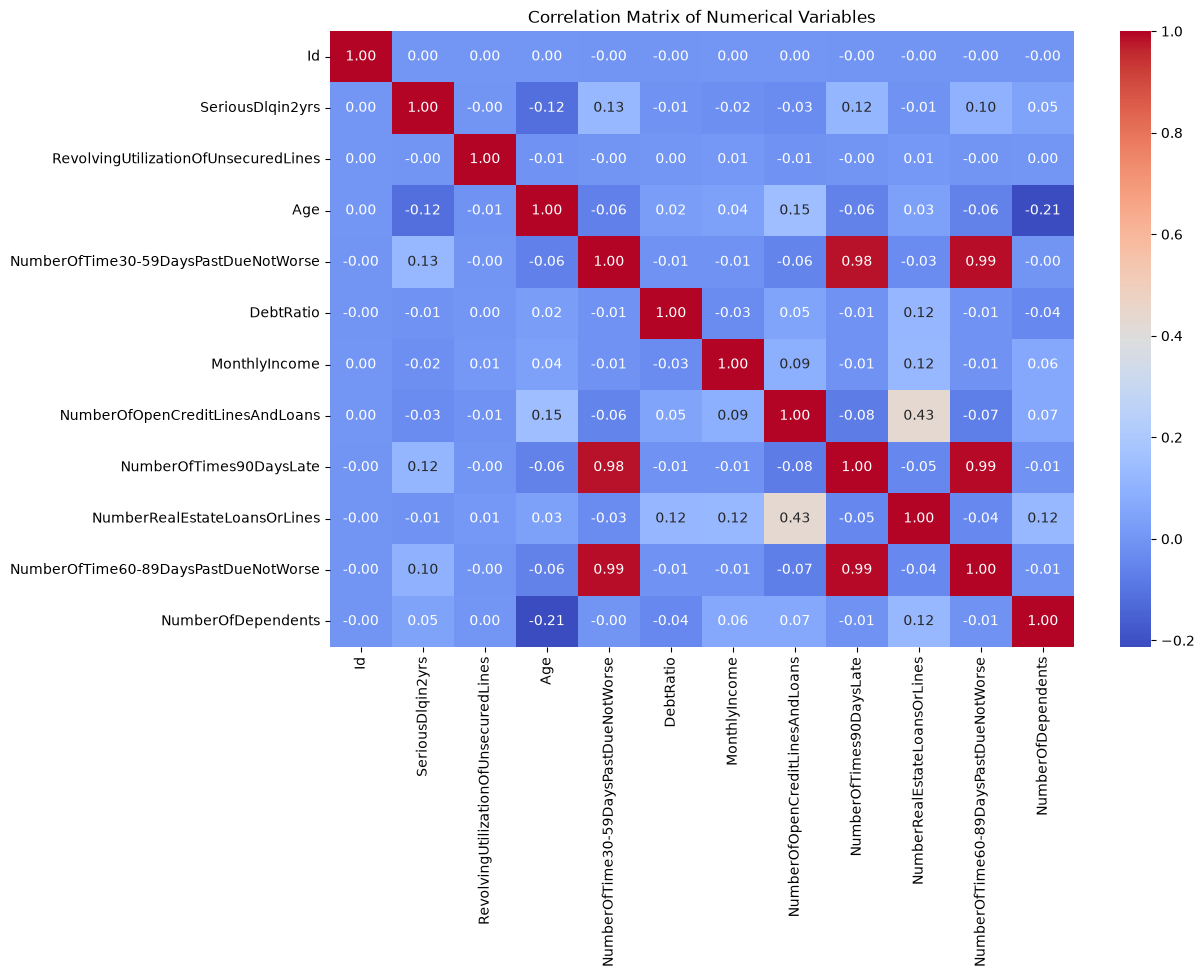

In [106]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()

In [107]:
target_corr = correlation_matrix["SeriousDlqin2yrs"].sort_values(ascending=True)
display(target_corr)

Age                                    -0.115386
NumberOfOpenCreditLinesAndLoans        -0.029669
MonthlyIncome                          -0.019746
DebtRatio                              -0.007602
NumberRealEstateLoansOrLines           -0.007038
RevolvingUtilizationOfUnsecuredLines   -0.001802
Id                                      0.002801
NumberOfDependents                      0.046048
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfTimes90DaysLate                 0.117175
NumberOfTime30-59DaysPastDueNotWorse    0.125587
SeriousDlqin2yrs                        1.000000
Name: SeriousDlqin2yrs, dtype: float64

In [108]:
df["Age"].min(), df["Age"].max()

(np.int64(0), np.int64(109))

In [109]:
df["MonthlyIncome"].min(), df["MonthlyIncome"].max()

(np.float64(0.0), np.float64(3008750.0))

In [110]:
df["DebtRatio"].min(), df["DebtRatio"].max()

(np.float64(0.0), np.float64(329664.0))

In [111]:
df["NumberOfDependents"].min(), df["NumberOfDependents"].max()

(np.float64(0.0), np.float64(20.0))

In [112]:
df["NumberOfTimes90DaysLate"].min(), df["NumberOfTimes90DaysLate"].max()

(np.int64(0), np.int64(98))

In [113]:
Q1 = df["MonthlyIncome"].quantile(0.25)
Q3 = df["MonthlyIncome"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -3873.5
Upper bound: 15522.5


In [114]:
outliers = df[
    (df["MonthlyIncome"] < lower_bound) |
    (df["MonthlyIncome"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 4879


In [115]:
quality_report = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Missing_Values": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100,
    "Unique_Values": df.nunique()
})

display(quality_report)
quality_report["Duplicate_Count"] = df.duplicated().sum()

,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
Id,int64,0,0.000000,150000
SeriousDlqin2yrs,int64,0,0.000000,2
RevolvingUtilizationOfUnsecuredLines,float64,0,0.000000,125728
Gender,str,149693,99.795333,2
Age,int64,0,0.000000,86
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000000,16
DebtRatio,float64,0,0.000000,114194
MonthlyIncome,float64,29731,19.820667,13594
NumberOfOpenCreditLinesAndLoans,int64,0,0.000000,58
NumberOfTimes90DaysLate,int64,0,0.000000,19


In [116]:
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(
    df["MonthlyIncome"].median()
)

In [117]:
df["NumberOfDependents"] = df["NumberOfDependents"].fillna(
    df["NumberOfDependents"].median()
)

In [118]:
df.isnull().sum()

Id                                           0
SeriousDlqin2yrs                             0
RevolvingUtilizationOfUnsecuredLines         0
Gender                                  149693
Age                                          0
NumberOfTime30-59DaysPastDueNotWorse         0
DebtRatio                                    0
MonthlyIncome                                0
NumberOfOpenCreditLinesAndLoans              0
NumberOfTimes90DaysLate                      0
NumberRealEstateLoansOrLines                 0
NumberOfTime60-89DaysPastDueNotWorse         0
NumberOfDependents                           0
dtype: int64

In [119]:
df.shape
df.describe()

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [120]:
numeric_df = df.select_dtypes(include=np.number)

correlation_with_target = (
    numeric_df.corr()["SeriousDlqin2yrs"]
    .sort_values(ascending=False)
)

display(correlation_with_target)

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046869
Id                                      0.002801
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.017151
NumberOfOpenCreditLinesAndLoans        -0.029669
Age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64

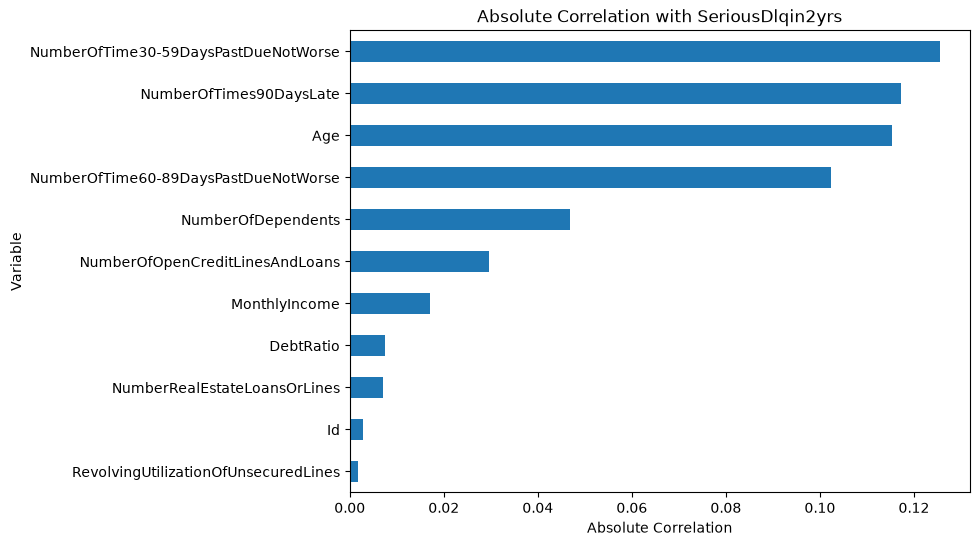

In [121]:
target_corr_abs = (
    df.select_dtypes(include=np.number)
      .corr()["SeriousDlqin2yrs"]
      .drop("SeriousDlqin2yrs")
      .abs()
      .sort_values(ascending=True)
)

plt.figure(figsize=(8, 6))

target_corr_abs.plot(kind="barh")

plt.title("Absolute Correlation with SeriousDlqin2yrs")
plt.xlabel("Absolute Correlation")
plt.ylabel("Variable")

plt.show()

In [122]:
important_cols = [
    "Age",
    "MonthlyIncome",
    "DebtRatio",
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents"
]

df.groupby("SeriousDlqin2yrs")[important_cols].mean().T

SeriousDlqin2yrs,0,1
Age,52.751375,45.926591
MonthlyIncome,6477.623137,5592.401456
DebtRatio,357.151168,295.121066
RevolvingUtilizationOfUnsecuredLines,6.168855,4.367282
NumberOfOpenCreditLinesAndLoans,8.493620,7.882306
NumberOfTimes90DaysLate,0.135225,2.091362
NumberOfTime60-89DaysPastDueNotWorse,0.126666,1.828047
NumberOfTime30-59DaysPastDueNotWorse,0.280109,2.388490
NumberRealEstateLoansOrLines,1.020368,0.988530
NumberOfDependents,0.723527,0.931279


In [123]:
pd.crosstab(
    df["NumberOfTimes90DaysLate"],
    df["SeriousDlqin2yrs"],
    normalize="index"
) * 100

#log use krain ga to woh symmetric hoga or standard scalar sa assymetric.

SeriousDlqin2yrs,0,1
NumberOfTimes90DaysLate,,
0,95.373495,4.626505
1,66.336067,33.663933
2,50.096463,49.903537
3,42.278861,57.721139
4,32.989691,67.010309
5,36.641221,63.358779
6,40.000000,60.000000
7,18.421053,81.578947
8,28.571429,71.428571


In [124]:
df.head(10)

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,Gender,Age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,f,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,m,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,f,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,m,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,f,49,1,0.024926,63588.0,7,0,1,0,0.0
5,6,0,0.213179,m,74,0,0.375607,3500.0,3,0,1,0,1.0
6,7,0,0.305682,m,57,0,5710.000000,5400.0,8,0,3,0,0.0
7,8,0,0.754464,NaN,39,0,0.209940,3500.0,8,0,0,0,0.0
8,9,0,0.116951,NaN,27,0,46.000000,5400.0,2,0,0,0,0.0
9,10,0,0.189169,NaN,57,0,0.606291,23684.0,9,0,4,0,2.0


In [132]:
df["Income_Group"] = pd.cut(
    df["MonthlyIncome"],
    bins=[ 1000, 5000, 15000, 30000, np.inf],
    labels=["Very Poor","Poor", "Middle", "Rich"]
)


In [133]:
display(df[['Income_Group']].head(10))

,Income_Group
0,Poor
1,Very Poor
2,Very Poor
3,Very Poor
4,Rich
5,Very Poor
6,Poor
7,Very Poor
8,Poor
9,Middle
